In [1]:
from pathlib import Path
import re

DATA_DIR = Path("dataset")
LABEL_NAMES = ["very negative", "negative", "neutral", "positive", "very positive"]


def parse_sst_tree(tree: str) -> tuple[str, int]:
    """Extract a sentence and its root label from an SST parse tree."""
    root_match = re.match(r"^\s*\(([0-4])\s", tree)
    if not root_match:
        raise ValueError(f"Invalid SST root: {tree[:60]!r}")

    leaf_tokens = re.findall(r"\([0-4]\s+([^()]+?)\)", tree)
    if not leaf_tokens:
        raise ValueError(f"No leaf tokens found: {tree[:60]!r}")

    text = " ".join(token.strip().replace(r"\/", "/") for token in leaf_tokens)
    text = text.replace("`` ", '"').replace(" ''", '"')
    text = re.sub(r"\s+([,.;:!?%\)])", r"\1", text)
    text = re.sub(r"([\(\[\{])\s+", r"\1", text)
    text = re.sub(r"\s+'\s*", "'", text)
    return text, int(root_match.group(1))


def load_sst_file(path: Path) -> list[dict[str, object]]:
    records = []
    for line_number, raw_line in enumerate(path.read_text(encoding="utf-8").splitlines(), start=1):
        if not raw_line.strip():
            continue
        try:
            text, label = parse_sst_tree(raw_line)
        except ValueError as error:
            raise ValueError(f"{path}:{line_number}: {error}") from error
        records.append({"text": text, "label": label})
    return records


train_records = load_sst_file(DATA_DIR / "train.txt")
dev_records = load_sst_file(DATA_DIR / "dev.txt")

# BERT Sentiment Analyzer

Fine-tune `bert-base-uncased` on the Stanford Sentiment Treebank (SST) files in `dataset/`. Each sentence receives its root label, from very negative (0) to very positive (4). Run cells in order on the H100, then save the notebook with outputs for submission.

In [2]:
from collections import Counter

import numpy as np
import torch
from datasets import Dataset, DatasetDict
from sklearn.metrics import accuracy_score, f1_score
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    DataCollatorWithPadding,
    Trainer,
    TrainingArguments,
    set_seed,
)

MODEL_NAME = "bert-base-uncased"
OUTPUT_DIR = "bert-sst5-output"
MAX_LENGTH = 128
set_seed(42)

label_to_id = {label: index for index, label in enumerate(LABEL_NAMES)}
id_to_label = {index: label for label, index in label_to_id.items()}

print(f"Model: {MODEL_NAME}")
print(f"CUDA available: {torch.cuda.is_available()}")
print(f"GPU: {torch.cuda.get_device_name(0)}")

/home/azureuser/lca-lc-foundations/Assignment3/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Model: bert-base-uncased
CUDA available: True
GPU: NVIDIA H100 NVL


## 1. Data Exploration

Train label distribution: {'very negative': 1092, 'negative': 2218, 'neutral': 1624, 'positive': 2322, 'very positive': 1288}
Dev label distribution:   {'very negative': 139, 'negative': 289, 'neutral': 229, 'positive': 279, 'very positive': 165}
DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 8544
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 1101
    })
})
Train: 8544 sentences; words min/median/max = 1/16/48
Dev: 1101 sentences; words min/median/max = 1/16/46


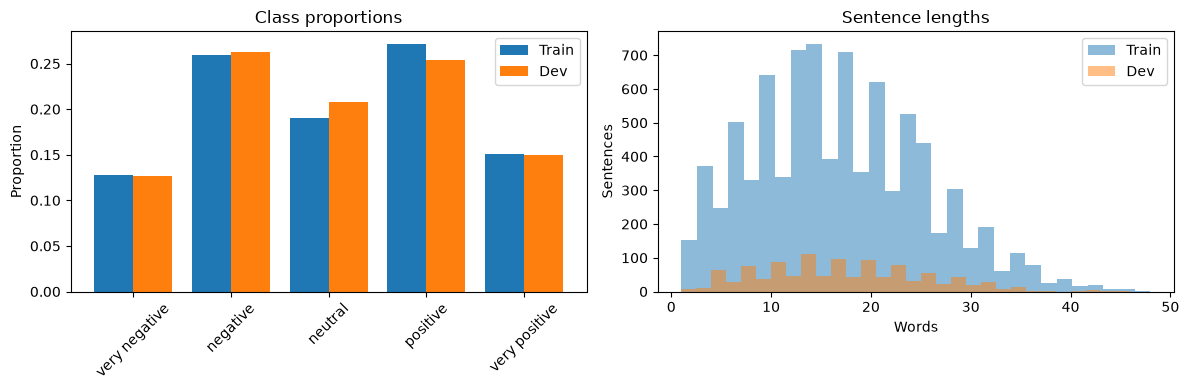

very negative: ... a sour little movie at its core; an exploration of the emptiness that underlay the relentless gaiety of the 1920's... The film's ending has a "What was it all for?"
negative: This is n't a new idea.
neutral: You'd think by now America would have had enough of plucky British eccentrics with hearts of gold.
positive: The Rock is destined to be the 21st Century's new "Conan" and that he's going to make a splash even greater than Arnold Schwarzenegger, Jean-Claud Van Damme or Steven Segal.
very positive: The gorgeously elaborate continuation of "The Lord of the Rings" trilogy is so huge that a column of words can not adequately describe co-writer/director Peter Jackson's expanded vision of J.R.R. Tolkien's Middle-earth.


In [ ]:
import matplotlib.pyplot as plt

# Keep all five classes in a fixed order so counts, plots, and label IDs align.
def summarize_labels(records: list[dict[str, object]]) -> dict[str, int]:
    counts = Counter(int(record["label"]) for record in records)
    return {LABEL_NAMES[label_id]: counts[label_id] for label_id in range(len(LABEL_NAMES))}


train_label_counts = summarize_labels(train_records)
dev_label_counts = summarize_labels(dev_records)
print("Train label distribution:", train_label_counts)
print("Dev label distribution:  ", dev_label_counts)

# Keep development examples separate for validation and checkpoint selection.
raw_datasets = DatasetDict(
    train=Dataset.from_list(train_records),
    validation=Dataset.from_list(dev_records),
)
print(raw_datasets)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
positions = np.arange(len(LABEL_NAMES))
for split, records, counts, offset in [("Train", train_records, train_label_counts, -0.2), ("Dev", dev_records, dev_label_counts, 0.2)]:

    lengths = np.array([len(row["text"].split()) for row in records])
    print(f"{split}: {len(records)} sentences; words min/median/max = {lengths.min()}/{np.median(lengths):.0f}/{lengths.max()}")
    # Compare proportions because train and development sets have different sizes.
    axes[0].bar(positions + offset, np.array(list(counts.values())) / len(records), width=0.4, label=split)
    axes[1].hist(lengths, bins=30, alpha=0.5, label=split)
axes[0].set(xticks=positions, xticklabels=LABEL_NAMES, title="Class proportions", ylabel="Proportion")
axes[0].tick_params(axis="x", rotation=45)
axes[1].set(title="Sentence lengths", xlabel="Words", ylabel="Sentences")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()
# Inspect one labeled training sentence per class to understand sentiment differences.
for label in range(len(LABEL_NAMES)):
    example = next(row for row in train_records if row["label"] == label)
    print(f"{LABEL_NAMES[label]}: {example['text']}")

## 2. Model Building

Transfer learning: load pretrained BERT and add a five-class classification head. Fine-tune all layers, rather than train from scratch or freeze BERT. I used truncation and dynamic padding. Train for 3 epochs with learning rate 2e-5, weight decay 0.01, and 10% warmup (`warmup_steps=0.1` in Transformers 5).

In [4]:
# Match token IDs to BERT's pretrained vocabulary and embeddings.
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize_batch(batch):
    # Truncate subword tokens; the data collator pads each batch later.
    return tokenizer(batch["text"], truncation=True, max_length=MAX_LENGTH)

tokenized_datasets = raw_datasets.map(tokenize_batch, batched=True, remove_columns=["text"])

# Macro-F1 weights all five sentiment classes equally, despite imbalance.
def compute_metrics(eval_prediction):
    logits, labels = eval_prediction
    predictions = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy_score(labels, predictions),
        "macro_f1": f1_score(labels, predictions, average="macro"),
    }


# Transfer learning: reuse BERT weights and add a new sentiment classifier.
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(LABEL_NAMES),
    id2label=id_to_label,
    label2id=label_to_id,
)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 6423.28it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoi

In [ ]:
training_args = TrainingArguments(
    output_dir=OUTPUT_DIR,
    num_train_epochs=3,
    per_device_train_batch_size=64,
    per_device_eval_batch_size=128,
    # Small updates help preserve BERT's pretrained representations.
    learning_rate=2e-5,
    weight_decay=0.01,
    # Transformers 5 interprets 0.1 as 10% of the total training steps.
    warmup_steps=0.1,
    # Use NVIDIA H100-supported bfloat16 mixed precision to reduce memory use.
    bf16=True,
    # Evaluate/save each epoch and reload the highest validation macro-F1 checkpoint.
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_steps=25,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    save_total_limit=2,
    report_to="none",
    dataloader_num_workers=4,
    seed=42,
)
# Configure the pipeline; optimization starts only when trainer.train() is called.
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_datasets["train"],
    eval_dataset=tokenized_datasets["validation"],
    processing_class=tokenizer,
    data_collator=DataCollatorWithPadding(tokenizer=tokenizer),
    compute_metrics=compute_metrics,
)

## Model Training

Fine-tune pretrained BERT on SST using mixed precision. 

In [6]:
trainer.train()
trainer.save_model(OUTPUT_DIR)
tokenizer.save_pretrained(OUTPUT_DIR)

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,1.226670,1.199762,0.443233,0.396832
2,1.020911,1.104284,0.508629,0.487456
3,0.921495,1.129968,0.513170,0.500902


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  4.74it/s]
[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'ber

('bert-sst5-output/tokenizer_config.json', 'bert-sst5-output/tokenizer.json')

## 3. Model Evaluation and Interpretation

Validation metrics: {'validation_loss': 1.1299679279327393, 'validation_accuracy': 0.5131698455949137, 'validation_macro_f1': 0.5009020792717911, 'validation_runtime': 0.3514, 'validation_samples_per_second': 3132.838, 'validation_steps_per_second': 25.609}
Majority baseline accuracy: 0.25340599455040874
               precision    recall  f1-score   support

very negative      0.484     0.432     0.456       139
     negative      0.542     0.599     0.569       289
      neutral      0.427     0.306     0.356       229
     positive      0.514     0.595     0.551       279
very positive      0.561     0.582     0.571       165

     accuracy                          0.513      1101
    macro avg      0.506     0.503     0.501      1101
 weighted avg      0.507     0.513     0.506      1101



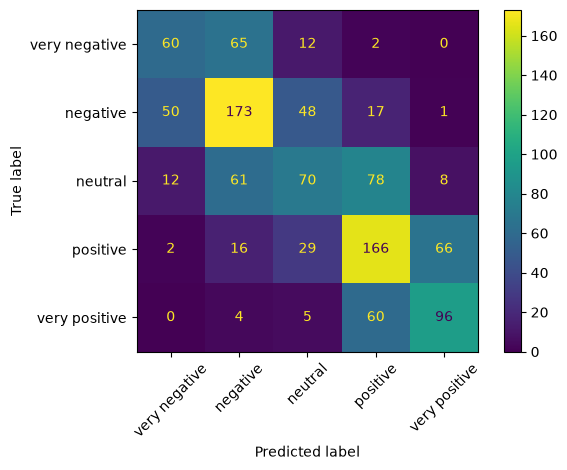

Most frequent confusion: neutral -> positive (78 sentences)
Correct predictions:
True: neutral; predicted: neutral | No one goes unindicted here, which is probably for the best.
True: very positive; predicted: very positive | A warm, funny, engaging film.
True: positive; predicted: positive | Entertains by providing good, lively company.
Misclassified examples:
True: positive; predicted: very positive | It's a lovely film with lovely performances by Buy and Accorsi.
True: positive; predicted: very positive | And if you're not nearly moved to tears by a couple of scenes, you've got ice water in your veins.
True: very positive; predicted: positive | Uses sharp humor and insight into human nature to examine class conflict, adolescent yearning, the roots of friendship and sexual identity.


In [ ]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay


validation = trainer.predict(trainer.eval_dataset, metric_key_prefix="validation")
labels, predictions = validation.label_ids, validation.predictions.argmax(axis=-1)
print("Validation metrics:", validation.metrics)
# Use the training-majority class as a baseline without consulting validation labels.
majority_id = np.bincount(raw_datasets["train"]["label"]).argmax()
print("Majority baseline accuracy:", accuracy_score(labels, np.full_like(labels, majority_id)))
# Report per-class precision/recall/F1; matrix rows are true labels and columns are predictions.
print(classification_report(labels, predictions, labels=range(len(LABEL_NAMES)), target_names=LABEL_NAMES, digits=3, zero_division=0))
display = ConfusionMatrixDisplay.from_predictions(labels, predictions, labels=range(len(LABEL_NAMES)), display_labels=LABEL_NAMES, xticks_rotation=45)
plt.tight_layout()
plt.show()
# Exclude the correct predictions on the diagonal to identify the most common confusion.
errors = display.confusion_matrix.copy()
np.fill_diagonal(errors, 0)
if errors.any():
    true_id, predicted_id = np.unravel_index(errors.argmax(), errors.shape)
    print(f"Most frequent confusion: {LABEL_NAMES[true_id]} -> {LABEL_NAMES[predicted_id]} ({errors.max()} sentences)")
# Inspect up to three correct and incorrect examples to interpret the model's behavior.
for correct in (True, False):
    print("Correct predictions:" if correct else "Misclassified examples:")
    for i in np.flatnonzero((predictions == labels) == correct)[:3]:
        print(f"True: {LABEL_NAMES[labels[i]]}; predicted: {LABEL_NAMES[predictions[i]]} | {dev_records[i]['text']}")